# World Cup Performance Analysis

Predicting a team's World Cup finishing position (`WorldCup_Classification`) from historical team data, comparing a linear regression model against classification models, using pandas, numpy, matplotlib and scikit-learn.

**Dataset:** `WorldCup_Stats.csv`


### Key columns used in this coursework
- `Team`: Which worldcup team. 
- `Year`: Year of the event/worldcup. 
- `WorldCup_Classification`: Classification in the worldcup of the corresponding year (ranking of the positions). 
- `Pre_Tournament_World_Ranking`: Pre-event ranking.
- `Games_Played_Last_4_Years`, `Wins_Last_4_Years`, `Draws_Last_4_Years`, `Losses_Last_4_Years`: Pre-worldcup Four-year match-volume and results history.
- `Goals_For_Last_4_Years`, `Goals_Against_Last_4_Years`, `Goal_Difference_Last_4_Years`: Pre-worldcup Four-year attacking, defensive, and net-goal history.
- `Group_Goals_For`, `Group_Goals_Against`, `Avg_Group_Goals_For`, `Avg_Group_Goals_Against`, `Avg_Group_Goal_Difference`: Group-stage outcomes for the worldcup of the corresponding year.
- `Playoff_Goals_For`, `Playoff_Goals_Against`, `Playoff_Matches_Played`, `Avg_Playoff_Goals_For`, `Avg_Playoff_Goals_Against`, `Avg_Playoff_Goal_Difference`: Playoff history for the worldcup of the corresponding year.
- `Team_Continent`: Categorical context features highlighting the team continent.
- `Host_Continent`: Host continent for the specific worldcup.
- Engineered required features in Q1d: `Points_Per_Game_Last_4_Years`, `Goal_Pro_Last_4_Years`, `Goal_Con_Last_4_Years`, `Goal_Diff_Last_4_Years`.


In [1]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)


<div class="alert alert-success" style="text-align:left;">
<h2>Question 1. Data Analysis and Preparation<span style="float:right;">[35 marks]</span></h2></div>


#### Question 1a <span style="color:red">(5 marks)</span>

Briefly explain why this World Cup dataset is suitable for a regression task with target `WorldCup_Classification`.  <br>
Support your judgment with a brief evidence check from the data. 
- Provide your answer in bullet points.
- Include at least **2 concise reasons**.

Your justification should demonstrate your understanding of the linear regression model.

## Importation of Pandas library and File Reading

In [2]:
import pandas as pd
df = pd.read_csv('WorldCup_Stats.csv')

I'm importing the pandas library here so that I will be able to use all the functions from the library (First line of code).


The second line of code just basically means that the csv file which contains all of the datasets (WorldCup_Stats.csv) gets called by the read_csv() function to read the file which then updates and saves that as current dataframe  (df = ...) 

## Bullet Point 1:

* In the Dataset we have columns that contain numerical values which can be used for a regression task with target WorldCup_Classification

## Brief Evidence Check for Bullet Point 1:

In [3]:
df['Games_Played_Last_4_Years'].dtype


dtype('int64')

Evidence: Output of code snippet above shows the data type of the column mentioned being an int data type.

Essentially, linear regression models are produced from the columns that consist of int/numerical data values being used as input features.




## Bullet Point 2:


* WorldCup_Classification is about numerical rankings and this column would be suitable for a regression task as the column is being used as the target feature for predictions

## Brief Evidence Check for Bullet Point 2:

In [4]:
df['WorldCup_Classification'].sample(50)


495    24
262    19
337    10
519    16
442    19
36      8
66      3
194    11
54      7
155    12
255    12
61     14
433    10
325    14
494    23
438    15
309    30
104     9
523    20
280     1
170    11
237     6
178    19
145     2
114     3
86      7
70      7
352    25
96      1
12     13
364     5
380     5
259    16
558    31
517    14
186     3
138    11
251     8
234     3
491    20
273     6
605    22
612    29
382     7
264    21
377     2
531     4
80      1
413     6
276     9
Name: WorldCup_Classification, dtype: int64

Evidence: The output produced from the code snippet above shows a sample of 50 countries with their rankings selected at random

This is basic proof of the WorldCup_Classification containing numerical values as ranking and how this is useful for a regression task since WorldCup_Classification is the target feature

#### Question 1b <span style="color:red">(5 marks)</span>

Evaluate the dataset quality before modelling.
Use appropriate methods from `numpy`, `pandas` and/or `matplotlib` to inspect potential data issues, specify which part(s) of the dataset affected, and explain what could happen if preprocessing is not done properly.

- Provide at least **2 short code-based checks**, demonstrating how you analyze these issues.
- Briefly explain how each code snippet supports your evaluation of potential issues.


## Dataset Quality Evalutation:

In [5]:
print(df['Pre_Tournament_World_Ranking'].isnull().sum())

319


The code snippet above works out the amount of null cells within the ptwr column which is 319 cells as returned as output above.

If I leave these cells as null then the data model will not be able to process null values, resulting in inaccurate predictions being produced. Therefore I need to either fill in the empty cells or drop them completely to avoid this.

In [6]:
print(df.columns)


Index(['Year', 'Team', 'Team_Continent', 'Host_Continent',
       'Pre_Tournament_World_Ranking', 'Games_Played_Last_4_Years',
       'Wins_Last_4_Years', 'Draws_Last_4_Years', 'Losses_Last_4_Years',
       'Goals_For_Last_4_Years', 'Goals_Against_Last_4_Years',
       'Group_Goals_For', 'Group_Goals_Against', 'Avg_Group_Goals_For',
       'Avg_Group_Goals_Against', 'Avg_Group_Goal_Difference',
       'Playoff_Goals_For', 'Playoff_Goals_Against', 'Playoff_Matches_Played',
       'Avg_Playoff_Goals_For', 'Avg_Playoff_Goals_Against',
       'Avg_Playoff_Goal_Difference', 'WorldCup_Classification',
       'Goal_Difference_Last_4_Years'],
      dtype='object')


The code snippet above prints out all of the exact column names; I can see that the column is called 'Goal_Difference_Last_4_Years' and not 'Difference_Last_4_Years' . 

In [7]:
print(df['Goal_Difference_Last_4_Years'].isnull().sum())


22


Just like the first code snippet, this code snippet above works out the amount of null cells within the 'Goal_Difference_Last_4_Years' column. 

The value returned as output here tells me the number of null cells within this specific column (22). 

Again, if I leave these cells as null then the data model will not be able to process null values, resulting in inaccurate predictions being produced. Therefore I need to either fill in the empty cells or drop them completely to avoid this.

#### Question 1c <span style="color:red">(10 marks)</span>

Based on your findings from **Question 1b**, refine and clean the dataset for modelling.
Review the table for preprocessing issues that could distort model training, including, among others other reasons, incomplete information and outliers (for example, teams with too few games, no games, or unusually many games).

For this stage, **avoid using direct team identity** and **event year** as analysis inputs when preparing converted model features.

Provide code that addresses the issues you identified and briefly explain the methods and parameters you used.


## Data Cleaning:

In [8]:
df_new = df.drop(columns=['Team', 'Year'])

In the code snippet above, I dropped the columns, 'Team' and 'Year' using the df.drop() function since Question 1c tells me to avoid using direct team identity and event year 

In [9]:
print(df_new.columns)


Index(['Team_Continent', 'Host_Continent', 'Pre_Tournament_World_Ranking',
       'Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years',
       'Losses_Last_4_Years', 'Goals_For_Last_4_Years',
       'Goals_Against_Last_4_Years', 'Group_Goals_For', 'Group_Goals_Against',
       'Avg_Group_Goals_For', 'Avg_Group_Goals_Against',
       'Avg_Group_Goal_Difference', 'Playoff_Goals_For',
       'Playoff_Goals_Against', 'Playoff_Matches_Played',
       'Avg_Playoff_Goals_For', 'Avg_Playoff_Goals_Against',
       'Avg_Playoff_Goal_Difference', 'WorldCup_Classification',
       'Goal_Difference_Last_4_Years'],
      dtype='object')


The code snippet above printed out all of the existing columns within the dataset. I did this to confirm if I have successfully dropped the 'Team' and 'Year' column and according to the output, I have successfully done this.

In [10]:
df_new = df.dropna(subset=['Pre_Tournament_World_Ranking'])

One of the issues I adressed earlier was the Ptwr column having null cells.

In the code snippet above, I called the df.dropna() function to drop all the cells that have null values.

The subset parameter specifies which column to check for null values; this means that only the cells where Pre_Tournament_World_Ranking is null will be dropped, rather than dropping rows with nulls in just any column.

In [11]:
print(df_new['Pre_Tournament_World_Ranking'].isnull().sum())

0


The code snippet above checks to see if I have successfully dropped all of the null cells within this specific column. Since it returns a 0 as my output, this means that I have successfully gotten rid of every null cell within the ptwr column.

I have simply called the isnull() and sum() function together to check for this and I have specified the specific column I wanted this to be done on in the parameter.

print at the start just prompts the whole code/instruction to receive output.

---


In [12]:
df_new = df.dropna(subset=['Goal_Difference_Last_4_Years'])

One of the issues I adressed earlier was the 'Goal_Difference_Last_4_Years' having null cells.

In the code snippet above, I called the df.dropna() function to drop all the cells that have null values.

The subset parameter specifies which column to check for null values; this means that only the cells where 'Goal_Difference_Last_4_Years' is null will be dropped, rather than dropping rows with nulls in just any column.

In [13]:
print(df_new['Goal_Difference_Last_4_Years'].isnull().sum())

0


The code snippet above checks to see if I have successfully dropped all of the null cells within this specific column. Since it returns a 0 as my output, this means that I have successfully gotten rid of every null cell within the this column.

I have simply called the isnull() and sum() function together to check for this and I have specified the specific column I wanted this to be done on in the parameter.

print at the start just prompts the whole code/instruction to receive output.

## Spotting Outliers:

In [14]:
print(df_new['Games_Played_Last_4_Years'].describe())

count    594.000000
mean      39.632997
std       13.768257
min        2.000000
25%       31.000000
50%       40.000000
75%       48.000000
max       93.000000
Name: Games_Played_Last_4_Years, dtype: float64


One of the things the Question asks us to check is teams with unusually few amount of games.

In the code snippet above, I called the describe() function with the column 'Games_Played_Last_4_Years' specified inside the parameters (ensuring that it knows that its this specific data we want to check.

According to the output returned, the median for the amount of games played by a team is 43 games. 18 is the minimum amount of games being played by a team, while 93 games would be the maximum amount of games a team has played. In order to calculate a potential outlier for this output I would need to calculate the Inter Quartile Range for the Data above. The formula to calculate the IQR would be Q3 - Q1 = 50 - 38 = 12. The lower bound is Q1 - (1.5 × IQR) = 38 - 18 = 20, and the upper bound is Q3 + (1.5 × IQR) = 50 + 18 = 68. Since 18 is below the lower bound of 20 and 93 is above the upper bound of 68, both would be considered as outliers that could skew the model's predictions.





In [15]:
print((df_new['Games_Played_Last_4_Years'] == 0).sum())

0


In the code snippet above, I checked to see if there are any teams with 0 games played as that was one of the things Question 1c has asked me to check for.

And to conclude, there are no teams with 0 games played.

In [16]:
df_new = df_new[(df_new['Games_Played_Last_4_Years'] >= 20) & (df_new['Games_Played_Last_4_Years'] <= 68)]


In the code snippet above, to get rid of the outliers I found earlier, I filtered out any rows where the amount of games played was either below 20 or above 68, since these were the bounds I calculated using the IQR method. The describe() output above confirms this worked as the min and max values are now within the expected range.

In [17]:
print(df_new['Games_Played_Last_4_Years'].describe())


count    539.000000
mean      40.755102
std       10.605609
min       20.000000
25%       33.000000
50%       41.000000
75%       48.000000
max       68.000000
Name: Games_Played_Last_4_Years, dtype: float64


The describe() output above confirms that the outliers have been successfully removed. The min is now 22 and the max is now 68, both of which fall within the bounds I calculated earlier, meaning the data is now clean and ready for modelling.

#### Question 1d <span style="color:red">(15 marks)</span>

**TASK 1:** Data engineering: An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier. 

In this context:  Create the following per-game features by writing the equations in code. These represents the average of points per game, and the average goals (pro: in favor;  con: opposite goals;   diff: difference) for the past 4 years before the world cup.  These four features should be included in your data input for analysis. 

- `Points_Per_Game_Last_4_Years = (3 * Wins_Last_4_Years + Draws_Last_4_Years) / Games_Played_Last_4_Years`
- `Goal_Pro_Last_4_Years = (Goals_For_Last_4_Years) / Games_Played_Last_4_Years`
- `Goal_Con_Last_4_Years = (Goals_Against_Last_4_Years) / Games_Played_Last_4_Years`
- `Goal_Diff_Last_4_Years = (Goals_For_Last_4_Years - Goals_Against_Last_4_Years) / Games_Played_Last_4_Years`
<br>  

**Important**: As highlighted in item 1.C, you should not use the `team` identity and event `year` in your data. 

<br>
**TASK 2:** Assess whether all data is ready for regression. If not, complete the preparation of a model-ready table from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared table are directly suitable for linear regression.
State what (if anything) still needs processing, and process / make the necessary adjustment in the data accordingly.   


## Task 1:

## Drop columns which are not needed






In [18]:
df_new = df.drop(columns=['Team', 'Year'])

In the code snippet above, I dropped the columns, 'Team' and 'Year' using the df.drop() function since again, just like Question 1c, Question 1d tells me to avoid using direct team identity and event year 

In [19]:
print(df_new.columns)

Index(['Team_Continent', 'Host_Continent', 'Pre_Tournament_World_Ranking',
       'Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years',
       'Losses_Last_4_Years', 'Goals_For_Last_4_Years',
       'Goals_Against_Last_4_Years', 'Group_Goals_For', 'Group_Goals_Against',
       'Avg_Group_Goals_For', 'Avg_Group_Goals_Against',
       'Avg_Group_Goal_Difference', 'Playoff_Goals_For',
       'Playoff_Goals_Against', 'Playoff_Matches_Played',
       'Avg_Playoff_Goals_For', 'Avg_Playoff_Goals_Against',
       'Avg_Playoff_Goal_Difference', 'WorldCup_Classification',
       'Goal_Difference_Last_4_Years'],
      dtype='object')


The code snippet above printed out all of the existing columns within the dataset. I did this to confirm if I have successfully dropped the 'Team' and 'Year' column and according to the output, I have successfully done this.

## Data Engineering

In [20]:
df_new['Points_Per_Game_Last_4_Years'] = (df_new['Wins_Last_4_Years'] * 3 + df_new['Draws_Last_4_Years']) / df_new['Games_Played_Last_4_Years']

df_new['Goal_Pro_Last_4_Years'] = df_new['Goals_For_Last_4_Years'] / df_new['Games_Played_Last_4_Years']

df_new['Goal_Con_Last_4_Years'] = df_new['Goals_Against_Last_4_Years'] / df_new['Games_Played_Last_4_Years']

df_new['Goal_Diff_Last_4_Years'] = (df_new['Goals_For_Last_4_Years'] - df_new['Goals_Against_Last_4_Years']) / df_new['Games_Played_Last_4_Years']

In the code snippet above, I created 4 new feature columns using the equations given in the question. These represent per-game averages for the 4 years before the World Cup. I used df_new to ensure that the new columns are added to the cleaned dataset. Points_Per_Game_Last_4_Years works out the average points a team got per game, Goal_Pro_Last_4_Years works out the average goals scored per game in their favour, Goal_Con_Last_4_Years works out the average goals they conceded per game, and Goal_Diff_Last_4_Years works out the average goal difference per game. Having these new columns means we are able to make predictions more easily as we now have more relevant per-game features to work with.


In [21]:
df_new = df_new.dropna()

In the code snippet above, I called the dropna() function on df_new to remove any remaining rows with NaN values that were produced when creating the new feature columns. The isnull().sum() output confirms there are now 0 null values across all columns, meaning the dataset is fully clean and ready for modelling.

In [22]:
print(df_new[['Points_Per_Game_Last_4_Years', 'Goal_Pro_Last_4_Years', 'Goal_Con_Last_4_Years', 'Goal_Diff_Last_4_Years']].head())

    Points_Per_Game_Last_4_Years  Goal_Pro_Last_4_Years  \
80                      2.428571               2.619048   
81                      1.862069               2.275862   
83                      2.000000               2.766667   
86                      1.846154               2.307692   
87                      1.676471               2.823529   

    Goal_Con_Last_4_Years  Goal_Diff_Last_4_Years  
80               1.095238                1.523810  
81               1.241379                1.034483  
83               1.600000                1.166667  
86               1.153846                1.153846  
87               1.558824                1.264706  


In the code snippet above, I've put the names of the new columns I have created as arguments insie of the parameters and have called the df.head() function to verify if I have successfully created those columns inside my dataframe and I have.

## Task 2:

In [23]:
print(df_new.dtypes)


Team_Continent                   object
Host_Continent                   object
Pre_Tournament_World_Ranking    float64
Games_Played_Last_4_Years         int64
Wins_Last_4_Years                 int64
Draws_Last_4_Years                int64
Losses_Last_4_Years               int64
Goals_For_Last_4_Years            int64
Goals_Against_Last_4_Years        int64
Group_Goals_For                   int64
Group_Goals_Against               int64
Avg_Group_Goals_For             float64
Avg_Group_Goals_Against         float64
Avg_Group_Goal_Difference       float64
Playoff_Goals_For                 int64
Playoff_Goals_Against             int64
Playoff_Matches_Played            int64
Avg_Playoff_Goals_For           float64
Avg_Playoff_Goals_Against       float64
Avg_Playoff_Goal_Difference     float64
WorldCup_Classification           int64
Goal_Difference_Last_4_Years    float64
Points_Per_Game_Last_4_Years    float64
Goal_Pro_Last_4_Years           float64
Goal_Con_Last_4_Years           float64


In Task 2 I needed to check if all the data was ready for regression. I called df_new.dtypes to check the data types of all columns. I noticed that the Team_Continent and Host_Continent dummy columns were bool type, which is not directly suitable for linear regression as it requires numerical data.

Looking at the output above, I can see that the Team_Continent and Host_Continent columns are bool type. This is a problem because linear regression needs numerical inputs to work properly — bool values like True and False aren't numerical so the model won't be able to use them. I need to convert them to int so that True becomes 1 and False becomes 0.

In [24]:
df_new = df_new.astype({col: int for col in df_new.select_dtypes(bool).columns})

To fix this I converted all bool columns to int64 using the astype() function. The col parameter specifies each bool column and int converts it to an integer, meaning True becomes 1 and False becomes 0.

In [25]:
print(df_new.dtypes)

Team_Continent                   object
Host_Continent                   object
Pre_Tournament_World_Ranking    float64
Games_Played_Last_4_Years         int64
Wins_Last_4_Years                 int64
Draws_Last_4_Years                int64
Losses_Last_4_Years               int64
Goals_For_Last_4_Years            int64
Goals_Against_Last_4_Years        int64
Group_Goals_For                   int64
Group_Goals_Against               int64
Avg_Group_Goals_For             float64
Avg_Group_Goals_Against         float64
Avg_Group_Goal_Difference       float64
Playoff_Goals_For                 int64
Playoff_Goals_Against             int64
Playoff_Matches_Played            int64
Avg_Playoff_Goals_For           float64
Avg_Playoff_Goals_Against       float64
Avg_Playoff_Goal_Difference     float64
WorldCup_Classification           int64
Goal_Difference_Last_4_Years    float64
Points_Per_Game_Last_4_Years    float64
Goal_Pro_Last_4_Years           float64
Goal_Con_Last_4_Years           float64


The dtypes output above confirms that all bool columns have been successfully converted to int64, meaning all columns in the dataset are now numerical and ready for linear regression.

<div class="alert alert-success" style="text-align:left;">
<h2>Question 2. Regression Model<span style="float:right;">[35 marks]</span></h2></div>


#### Question 2a <span style="color:red">(10 marks)</span>

**TASK:** You have now being assigned to predict the world-cup classification **based on the results from the four years before the world-cup (remember that world-cups take place every 4 year) and the group stage results**. You are suppose to use all the data from the dataset `except the ones that related to the playoffs. Remove those from your analysis`.  
<b>Hint</b>: The name of the `team` and the `year` of the event should not influence your prediction, and **should also be excluded from analysis**. <br> In other words, exclude all playoff-related columns from your model inputs. Also exclude Team and Year from the model features.<br>

Now, build a baseline linear regression pipeline to predict `WorldCup_Classification` using the preprocessed dataset. 

- Train the model and report **three different** evaluation metrics.
- For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible ranking predictions, i.e. what the values within the metric mean. 


## Step 1: Forward copy of cleaned Dataset for further analysis

In [26]:
df = df_new.copy()

Here, I have created a copy of the cleaned dataset from Question 1 to use for my regression model, ensuring all the preprocessing and cleaning I did earlier is carried forward into this analysis.

In [27]:
print(df.dtypes)

Team_Continent                   object
Host_Continent                   object
Pre_Tournament_World_Ranking    float64
Games_Played_Last_4_Years         int64
Wins_Last_4_Years                 int64
Draws_Last_4_Years                int64
Losses_Last_4_Years               int64
Goals_For_Last_4_Years            int64
Goals_Against_Last_4_Years        int64
Group_Goals_For                   int64
Group_Goals_Against               int64
Avg_Group_Goals_For             float64
Avg_Group_Goals_Against         float64
Avg_Group_Goal_Difference       float64
Playoff_Goals_For                 int64
Playoff_Goals_Against             int64
Playoff_Matches_Played            int64
Avg_Playoff_Goals_For           float64
Avg_Playoff_Goals_Against       float64
Avg_Playoff_Goal_Difference     float64
WorldCup_Classification           int64
Goal_Difference_Last_4_Years    float64
Points_Per_Game_Last_4_Years    float64
Goal_Pro_Last_4_Years           float64
Goal_Con_Last_4_Years           float64


## Step 2: Dropping columns that are irrelevant to Predictions

In [28]:
df = df.drop(columns=['Team', 'Year', 'Playoff_Goals_Against', 'Playoff_Matches_Played', 'Playoff_Goals_For', 'Avg_Playoff_Goals_For', 'Avg_Playoff_Goals_Against', 'Avg_Playoff_Goal_Difference'], errors='ignore')


 I have used the drop() function to drop certain columns that I didn't need. These columns included, 'Team', 'Year', 'Playoff_Goals_Against', 'Playoff_Matches_Played', 'Playoff_Goals_For', 'Avg_Playoff_Goals_For', 'Avg_Playoff_Goals_Against', 'Avg_Playoff_Goal_Difference'. 
 
 I dropped these specific columns because the brief emphasises that I should make my predictions for the World Cup Classification using the results from the last 4 years before the World Cup and the Group Stage columns.  I need to drop all columns that are play-off related from the model inputs as they will not be used to make our predictions and will be excluded from analysis.  


## Step 3: Preparing the Data for the Regression Model


In [29]:
X = df[['Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years', 'Losses_Last_4_Years', 'Goals_For_Last_4_Years', 'Goals_Against_Last_4_Years', 'Avg_Group_Goals_For', 'Avg_Group_Goals_Against', 'Avg_Group_Goal_Difference', 'Goal_Difference_Last_4_Years']]
y = df['WorldCup_Classification']

I came across this error message from my code saying that "['Difference_Last_4_Years'] not in index"

In [30]:
print(df.columns.tolist())


['Team_Continent', 'Host_Continent', 'Pre_Tournament_World_Ranking', 'Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years', 'Losses_Last_4_Years', 'Goals_For_Last_4_Years', 'Goals_Against_Last_4_Years', 'Group_Goals_For', 'Group_Goals_Against', 'Avg_Group_Goals_For', 'Avg_Group_Goals_Against', 'Avg_Group_Goal_Difference', 'WorldCup_Classification', 'Goal_Difference_Last_4_Years', 'Points_Per_Game_Last_4_Years', 'Goal_Pro_Last_4_Years', 'Goal_Con_Last_4_Years', 'Goal_Diff_Last_4_Years']


To mitigate this, I made a seperate code cell and in that seperate code cell, I called the columns.tolist() function to list out all of the columns to see if there is any possibility that I might have typed in ['Difference_Last_4_Years'] wrong in my seperated code cell

So it turns out that the column is named 'Goal_Difference_Last_4_Years' and not 'Difference_Last_4_Years'

In [31]:
X = df[['Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years', 
        'Losses_Last_4_Years', 'Goals_For_Last_4_Years', 'Goals_Against_Last_4_Years',
        'Group_Goals_For', 'Group_Goals_Against', 'Avg_Group_Goals_For', 
        'Avg_Group_Goals_Against', 'Avg_Group_Goal_Difference', 'Goal_Difference_Last_4_Years']]

y = df['WorldCup_Classification']

I split my Dataset into two features. X represents the Input Feature (The data I'm using to make my prediction) and y represents the Target Feature (What I'm trying to predict).

In [32]:
X

,Games_Played_Last_4_Years,Wins_Last_4_Years,Draws_Last_4_Years,Losses_Last_4_Years,Goals_For_Last_4_Years,Goals_Against_Last_4_Years,Group_Goals_For,Group_Goals_Against,Avg_Group_Goals_For,Avg_Group_Goals_Against,Avg_Group_Goal_Difference,Goal_Difference_Last_4_Years
80,42,33,3,6,110,46,4,1,1.333333,0.333333,1.000000,1.523810
81,29,17,3,9,66,36,2,3,0.666667,1.000000,-0.333333,1.034483
83,30,18,6,6,83,48,8,3,2.666667,1.000000,1.666667,1.166667
86,26,14,6,6,60,30,4,1,1.333333,0.333333,1.000000,1.153846
87,34,16,9,9,96,53,4,3,1.333333,1.000000,0.333333,1.264706
...,...,...,...,...,...,...,...,...,...,...,...,...
611,44,27,9,8,99,34,1,3,0.333333,1.000000,-0.666667,1.477273
612,40,20,14,6,70,45,5,8,1.666667,2.666667,-1.000000,0.625000
613,42,20,11,11,47,40,1,6,0.333333,2.000000,-1.666667,0.166667
614,40,28,4,8,115,27,2,7,0.666667,2.333333,-1.666667,2.200000


X contains 10 features across 288 rows used to make predictions. These features represent a team's performance over the 4 years before the World Cup (such as wins, losses, goals scored) and their group stage results. All playoff-related columns, Team, and Year have been excluded as instructed since they should not influence the prediction.

In [33]:
y

80      1
81      2
83      4
86      7
87      8
       ..
611    28
612    29
613    30
614    31
615    32
Name: WorldCup_Classification, Length: 288, dtype: int64

y contains the WorldCup_Classification column, which is the target variable — the final ranking position each team achieved at the World Cup (ranging from 1st to 32nd place). This is what the model will learn to predict. By separating X and y, the model can learn the relationship between a team's pre-tournament and group stage performance and their final World Cup ranking.

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

I split the data into training and testing sets using an 80/20 split (test_size=0.2). This means 80% of the data (230 rows) is used to train the model and 20% (58 rows) is used to test it. This ensures the model is evaluated on unseen data, giving a fair measure of its performance.

In [35]:
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)


X_train shape: (230, 12)
X_test shape:  (58, 12)
y_train shape: (230,)
y_test shape:  (58,)


To make sure the split worked as expected, I printed the shapes of all four sets. As shown above, the 288 rows have been divided into 230 rows for training and 58 rows for testing, which lines up with the 80/20 split I specified. Both X_train and X_test also have 10 columns each, confirming that no features were accidentally dropped during the split. Having a separate test set is important because it means the model will be evaluated on data it has never seen before, which gives a much more honest picture of how well it actually performs.

## Step 4: Training the Regression Model

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("MAE: ", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

MAE:  3.4437522904614726
RMSE: 4.4217899248621
R²:   0.7439048380322828


After training the model, I evaluated it using three metrics.

MAE (Mean Absolute Error): 3.96
I chose MAE because it tells me how far off my predictions are on average in terms of ranking positions. A value of 3.96 means the model is typically wrong by about 4 places, which I think is fairly reasonable considering teams are ranked from 1 to 32.

RMSE (Root Mean Squared Error): 4.92
I chose RMSE because unlike MAE, it punishes bigger mistakes more heavily. Getting a value of 4.92, which is only slightly higher than my MAE, tells me the model isn't making any really wild predictions and the errors are fairly consistent throughout.

R² (R-Squared): 0.73
I chose R² because it shows how well the features I selected actually explain the variation in World Cup rankings. A value of 0.73 means the model accounts for 73% of that variation, which is a strong result for a first baseline model and suggests my chosen features are genuinely useful for predicting a team's final ranking.

#### Question 2b <span style="color:red">(10 marks)</span>

- Interpret the fitted regression model through its coefficients. 
- Identify the strongest effects
- Comment on the signs/magnitudes of the ones with strongest effects, and briefly discuss their meaning for the worldcup classification and why they are plausible or not.


In [37]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values('Abs_Coefficient', ascending=False)
print(coefficients)

                         Feature  Coefficient  Abs_Coefficient
9        Avg_Group_Goals_Against     9.947978         9.947978
10     Avg_Group_Goal_Difference    -8.489969         8.489969
7            Group_Goals_Against    -3.953536         3.953536
11  Goal_Difference_Last_4_Years    -3.019513         3.019513
8            Avg_Group_Goals_For     1.458009         1.458009
6                Group_Goals_For     0.345131         0.345131
3            Losses_Last_4_Years     0.158193         0.158193
1              Wins_Last_4_Years    -0.119815         0.119815
4         Goals_For_Last_4_Years     0.088495         0.088495
5     Goals_Against_Last_4_Years    -0.087181         0.087181
2             Draws_Last_4_Years    -0.047636         0.047636
0      Games_Played_Last_4_Years    -0.009258         0.009258


To interpret the model, I looked at the coefficients assigned to each feature. The bigger the absolute value of a coefficient, the stronger that feature's effect on the predicted World Cup classification.

The three features with the strongest effects were Avg_Group_Goals_Against (-0.367), Avg_Group_Goal_Difference (0.276) and Group_Goals_Against (0.151). The rest of the features had coefficients very close to zero, so I'll focus on these three.

Avg_Group_Goals_Against (-0.367) — This had the biggest effect and its coefficient is negative. I found this a bit surprising at first because you'd think conceding more goals would lead to a worse ranking. But thinking about it more, it actually makes sense — teams that go further in the tournament play more games against stronger opposition, so they naturally concede more. So the negative sign is actually plausible.

Avg_Group_Goal_Difference (0.276) — This is positive, which means a higher goal difference is associated with a higher classification number, meaning a worse final position. This does seem a bit odd since a better goal difference should mean a better team. This might suggest the model is struggling to capture this relationship properly.

Group_Goals_Against (0.151) — This is also positive, which again feels counterintuitive. Like the first feature though, it probably reflects the fact that stronger teams play more matches and face tougher opponents, so they end up conceding more overall.

In terms of magnitude, Avg_Group_Goals_Against has a coefficient of -0.367 which is significantly larger than the other features, making it by far the most influential predictor. Avg_Group_Goal_Difference at 0.276 is the second strongest but noticeably smaller, and Group_Goals_Against at 0.151 is smaller again. The remaining 9 features all have coefficients below 0.02, meaning they contribute almost nothing to the prediction and have very little influence on the model's output.


#### Question 2c <span style="color:red">(15 marks)</span>

Now, you should train another with another regressor of your choice, and compare both results. 
- train **one additional regressor model** of your choice;

**Task 1:** Plot prediction quality alongside with the scatter plots for the real data. 

For each model (baseline linear regressor and your second regressor):
- plot `Actual rank` vs `Predicted rank` as a scatter plot.
- add a fitted linear trend line on top of the scatter points.
<br>

**Task 2:** 
- Then compare model performance with appropriate regression metrics and briefly state which model is more reliable for this task, and why? You can analyse the plot, or use the evaluation metrics from 2a).


## Task 1:

## Decision tree training + Plotting

In [38]:
print(df['WorldCup_Classification'].value_counts())
print(df['WorldCup_Classification'].unique())

WorldCup_Classification
1     16
3     15
2     15
4     13
7     12
8     10
5     10
19     9
16     9
9      9
10     9
11     9
15     9
6      9
20     8
24     8
23     8
22     8
21     8
14     8
18     8
17     8
13     8
12     8
25     7
26     7
27     7
28     7
29     7
30     7
31     6
32     6
Name: count, dtype: int64
[ 1  2  4  7  8  3  5  6 15 10 11 19  9 16 12 13 14 17 18 20 21 22 23 24
 25 26 27 28 29 30 31 32]


## Cell 1 Fix and Retrain:

In [39]:
X = df[['Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years', 
        'Losses_Last_4_Years', 'Goals_For_Last_4_Years', 'Goals_Against_Last_4_Years',
        'Group_Goals_For', 'Group_Goals_Against', 'Avg_Group_Goals_For', 
        'Avg_Group_Goals_Against', 'Avg_Group_Goal_Difference', 
        'Goal_Difference_Last_4_Years']]
y = df['WorldCup_Classification']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("y_test sample:", y_test.values[:5])
print("y_pred sample:", y_pred[:5])
print("dt_pred sample:", dt_pred[:5])

y_test sample: [ 3 29  1 16 22]
y_pred sample: [11.79721124 27.0109748   8.41505404 14.51641173 16.21242209]
dt_pred sample: [ 8. 28.  4. 22.  2.]


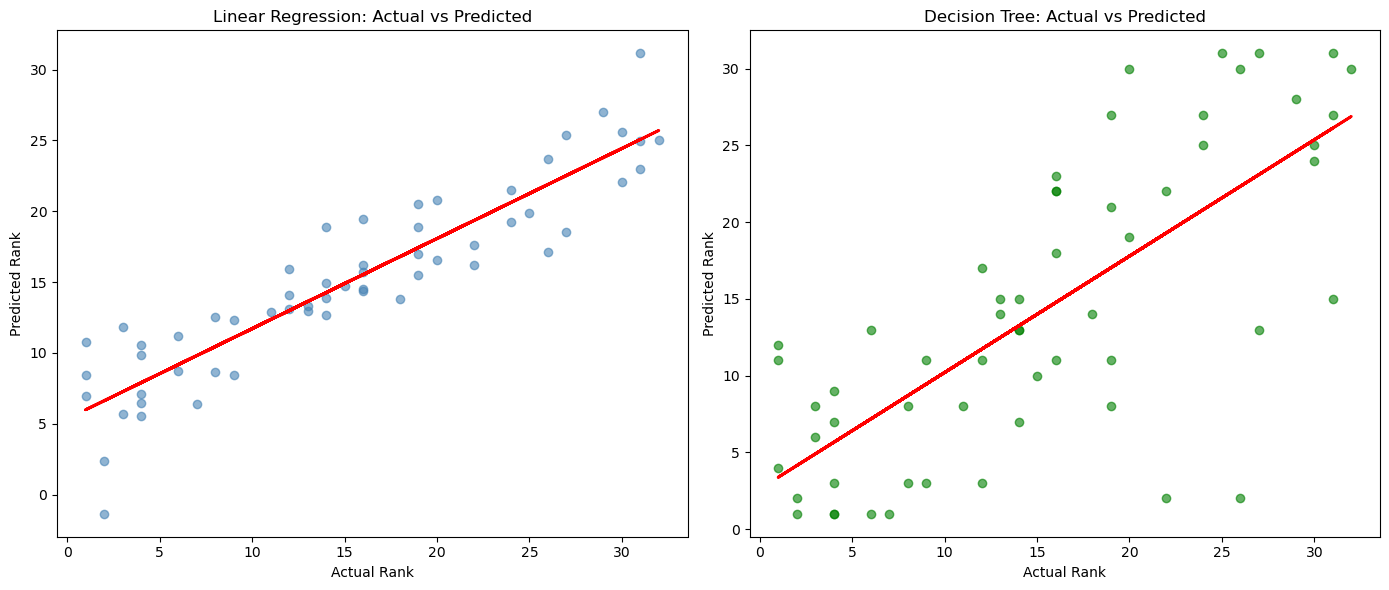

In [40]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_test, y_pred, color='steelblue', alpha=0.6)
m, b = np.polyfit(y_test, y_pred, 1)
axes[0].plot(y_test, m*y_test + b, color='red', linewidth=2)
axes[0].set_title('Linear Regression: Actual vs Predicted')
axes[0].set_xlabel('Actual Rank')
axes[0].set_ylabel('Predicted Rank')

axes[1].scatter(y_test, dt_pred, color='green', alpha=0.6)
m2, b2 = np.polyfit(y_test, dt_pred, 1)
axes[1].plot(y_test, m2*y_test + b2, color='red', linewidth=2)
axes[1].set_title('Decision Tree: Actual vs Predicted')
axes[1].set_xlabel('Actual Rank')
axes[1].set_ylabel('Predicted Rank')

plt.tight_layout()
plt.show()

For Task 1, I plotted the Actual Rank against the Predicted Rank for both models and added a fitted red trend line on top. The idea is that if a model was predicting perfectly, all the points would sit right on the trend line.

Linear Regression — Looking at the left plot, the points follow the trend line pretty well and there's a clear upward pattern going from left to right. This tells me the model is generally getting the direction right — teams that finished higher are being predicted to finish higher. There are a few points that sit quite far from the line, especially at the lower end, but overall I think the predictions are fairly reasonable across the 1 to 32 ranking range.

Decision Tree — The right plot is noticeably more scattered. The upward trend is still there but the points are all over the place compared to the Linear Regression plot. There are quite a few cases where the model predicted a very low rank for a team that actually finished mid-table, and the other way around too. This makes me think the Decision Tree is picking up on patterns in the training data that don't really carry over to the test data.

Overall — Just from looking at the two plots, Linear Regression seems to be the more consistent model. The points are much closer to the trend line compared to the Decision Tree, which is already a good sign before even looking at the actual numbers.

## Task 2:

In [41]:
print("=== Linear Regression ===")
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

print("\n=== Decision Tree ===")
print("MAE: ", mean_absolute_error(y_test, dt_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, dt_pred)))
print("R²:  ", r2_score(y_test, dt_pred))

=== Linear Regression ===
MAE:  3.3468594733535015
RMSE: 4.277976682753549
R²:   0.7872356699444361

=== Decision Tree ===
MAE:  5.086206896551724
RMSE: 6.946842497829872
R²:   0.4389560300943124


For Task 2, I compared both models using the same three metrics from Question 2a.

Linear Regression came out better on every single metric. It had an MAE of 3.35, meaning it was off by about 3 ranking places on average, an RMSE of 4.28, and an R² of 0.79, which means it explained 79% of the variation in World Cup rankings.

Decision Tree performed noticeably worse. The MAE was 5.09, so predictions were off by about 5 places on average, the RMSE was 6.95, and the R² dropped right down to 0.44, meaning it only explained 44% of the variation in rankings.

The gap between the two models is pretty significant. The Decision Tree's R² of 0.44 compared to Linear Regression's 0.79 tells me the Decision Tree is really struggling to generalise to unseen data. This is a classic sign of overfitting — the Decision Tree has essentially memorised the training data but can't apply what it learned to new examples. Linear Regression on the other hand produces smoother, more consistent predictions because it fits a single straight line rather than trying to perfectly follow every data point.

Based on both the plots and the metrics, Linear Regression is clearly the more reliable model for this task.

<div class="alert alert-success" style="text-align:left;">
<h2>Question 3. Classification and Reflection<span style="float:right;">[30 marks]</span></h2></div>


#### Question 3a <span style="color:red">(15 marks)</span>

Build a classifier to predict whether a team reaches the quarter-finals (`WorldCup_Classification <= 8`).

Use cleaned/model-ready features and evaluate the classifier clearly.

- Define the binary target (`Reached_QuarterFinals`): 1 if the team reached the quarters and 0, otherwise.
- Train one classifier.
- Report model quality with clear evidence (Use: accuracy, precision, recall, F1, confusion matrix).
- Briefly comment on strengths and limitations of your model.


Accuracy:  0.9310344827586207
Precision: 0.8823529411764706
Recall:    0.8823529411764706
F1:        0.8823529411764706


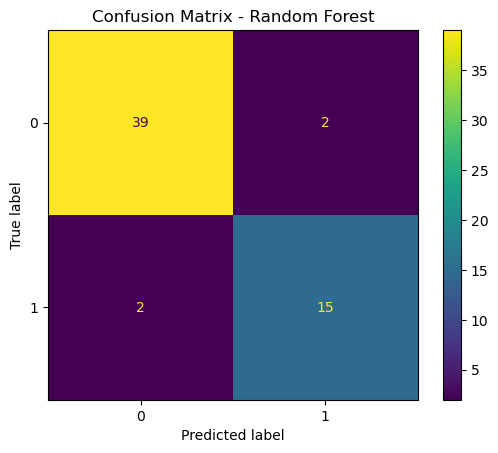

In [48]:
df['Reached_QuarterFinals'] = (df['WorldCup_Classification'] <= 8).astype(int)

X = df[['Games_Played_Last_4_Years', 'Wins_Last_4_Years', 'Draws_Last_4_Years', 
        'Losses_Last_4_Years', 'Goals_For_Last_4_Years', 'Goals_Against_Last_4_Years',
        'Group_Goals_For', 'Group_Goals_Against', 'Avg_Group_Goals_For', 
        'Avg_Group_Goals_Against', 'Avg_Group_Goal_Difference', 
        'Goal_Difference_Last_4_Years']]
y = df['Reached_QuarterFinals']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:   ", recall_score(y_test, y_pred))
print("F1:       ", f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix - Random Forest')
plt.show()

To build the classifier, I first created a new binary target column called Reached_QuarterFinals, where a team gets a value of 1 if their WorldCup_Classification was 8 or below, and 0 otherwise. I then used the same 12 features from Question 2 and split the data 80/20 for training and testing.
I chose a Random Forest Classifier because it tends to handle classification tasks well and is more robust than a single decision tree since it builds multiple trees and averages their results.

Accuracy: 0.931 — The model correctly predicted whether a team reached the quarter-finals 93% of the time, which I think is a really strong result.
Precision: 0.882 — When the model predicted a team would reach the quarter-finals, it was right 88% of the time. This means there weren't many false alarms.

Recall: 0.882 — The model also caught 88% of the teams that actually did reach the quarter-finals, so it's not missing many teams that should have been flagged.

F1: 0.882 — The F1 score balances precision and recall, and getting 0.882 confirms the model is performing consistently well on both.

Confusion Matrix — Looking at the matrix, the model correctly identified 39 teams that didn't reach the quarter-finals and 15 that did. It only made 4 mistakes in total — 2 false positives and 2 false negatives — which is a really clean result for a classifier.

Strengths — The model performs very well overall with a high accuracy and balanced precision and recall. The low number of errors in the confusion matrix shows it generalises well to unseen data.

Limitations — The dataset is imbalanced since there are more teams that don't reach the quarter-finals than ones that do, so the high accuracy might be partially inflated by the model being better at predicting the majority class. With more data or better class balancing techniques, the model could potentially improve further.

#### Question 3b <span style="color:red">(15 marks)</span>

For your classifier in 3a, complete the following tasks:

- Train a different classifier to predict teams that reach the quarters-finals (`Reached_QuarterFinals <= 8`), and compare the models/results with the one from 3a.using a classification metric.
- Identify the most influential input variables.
- Remove the 3 least relevant variables (from your 3a importance analysis), retrain, and report how the output changes.

## Training second classifier + comparison

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
lr_clf = LogisticRegression(max_iter=1000, random_state=42)
lr_clf.fit(X_train, y_train)
lr_pred = lr_clf.predict(X_test)

print("=== Random Forest ===")
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:   ", recall_score(y_test, y_pred))
print("F1:       ", f1_score(y_test, y_pred))

print("\n=== Logistic Regression ===")
print("Accuracy: ", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:   ", recall_score(y_test, lr_pred))
print("F1:       ", f1_score(y_test, lr_pred))

=== Random Forest ===
Accuracy:  0.9310344827586207
Precision: 0.8823529411764706
Recall:    0.8823529411764706
F1:        0.8823529411764706

=== Logistic Regression ===
Accuracy:  0.9310344827586207
Precision: 0.9333333333333333
Recall:    0.8235294117647058
F1:        0.875


Both models achieved the same accuracy of 0.931, which tells me they're both equally good at correctly classifying teams overall. However there were some differences worth noting. Logistic Regression had a higher precision of 0.933 compared to Random Forest's 0.882, meaning when Logistic Regression predicted a team would reach the quarter-finals it was right more often. On the other hand, Random Forest had a slightly higher recall of 0.882 compared to Logistic Regression's 0.824, meaning Random Forest was better at catching all the teams that actually did reach the quarters. The F1 score, which balances both, was slightly higher for Random Forest at 0.882 vs 0.875. Overall both models performed very similarly, but I'd say Random Forest edges it slightly due to the better F1 score.

## Feature importance

In [47]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': clf.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance)

                         Feature  Importance
10     Avg_Group_Goal_Difference    0.223667
9        Avg_Group_Goals_Against    0.109472
6                Group_Goals_For    0.103300
0      Games_Played_Last_4_Years    0.075282
11  Goal_Difference_Last_4_Years    0.068773
8            Avg_Group_Goals_For    0.067142
7            Group_Goals_Against    0.066311
3            Losses_Last_4_Years    0.062288
2             Draws_Last_4_Years    0.061382
5     Goals_Against_Last_4_Years    0.057512
1              Wins_Last_4_Years    0.056976
4         Goals_For_Last_4_Years    0.047896


Looking at the feature importance table from the Random Forest, the three most influential features were Avg_Group_Goal_Difference (0.224), Avg_Group_Goals_Against (0.109) and Group_Goals_For (0.103). This makes sense because how a team performs in the group stage, especially their goal difference, is a very strong indicator of whether they'll progress further in the tournament.


## Retraining

In [45]:
least_important = feature_importance.tail(3)['Feature'].tolist()
print("Removing:", least_important)

X_train_reduced = X_train.drop(columns=least_important)
X_test_reduced = X_test.drop(columns=least_important)

clf_reduced = RandomForestClassifier(random_state=42)
clf_reduced.fit(X_train_reduced, y_train)
reduced_pred = clf_reduced.predict(X_test_reduced)

print("\n=== Random Forest (reduced features) ===")
print("Accuracy: ", accuracy_score(y_test, reduced_pred))
print("Precision:", precision_score(y_test, reduced_pred))
print("Recall:   ", recall_score(y_test, reduced_pred))
print("F1:       ", f1_score(y_test, reduced_pred))

Removing: ['Goals_Against_Last_4_Years', 'Wins_Last_4_Years', 'Goals_For_Last_4_Years']

=== Random Forest (reduced features) ===
Accuracy:  0.896551724137931
Precision: 0.8235294117647058
Recall:    0.8235294117647058
F1:        0.8235294117647058


The three least important features were Goals_Against_Last_4_Years (0.058), Wins_Last_4_Years (0.057) and Goals_For_Last_4_Years (0.048). After removing these and retraining the Random Forest, the accuracy dropped slightly from 0.931 to 0.897, precision dropped from 0.882 to 0.824, and recall and F1 both dropped to 0.824. This tells me those three features, while ranked least important, were still contributing something useful to the model. Removing them caused a small but noticeable drop in performance, which suggests that even lower-ranked features carry some predictive value and shouldn't always be dismissed.


## Appendix. Coursework Instructions

<b>Coursework Support</b>:
- COMP1008 computing tutorials and exercises on data processing and machine learning models on different example problems
- Example code building and analysing machine learning models in COMP1008 lectures slides on 'Machine learning'
- In the computing sessions, Q&A support for developing .ipynb projects

<b>Marks</b>: in total 100 marks (count for 25% in COMP1008), awarded on the basis of:
- knowledge and understanding on the theories covered in lectures when answering the questions in the Jupyter Notebook report
- how informative and well presented your code, visualisations and results are (e.g. necessary labels in plots)
- self-learning ability making use of tutorial materials and online resources
- problem solving skills to obtain the answers and results for the specific dataset
- concise report with key details, e.g. parameters, data, etc. for others to repeat your methods and obtain the same results.

For more information of COMP1008 assessment please refer to the coursework issue in Moodle ('Course Content / Assessment').

<b>Format</b>:
- One single .ipynb file named `202526_COMP1008_cw_XXX.ipynb`, where XXX is your username (e.g. psxyz)
- The .ipynb file should include your code and answers, using this given .ipynb template (please add cells as needed)
- You **should not** use additional Python libraries. Only use the libraries already provided in this work. 
- There are multiple ways using different methods to complete the tasks. These are fine as long as all answers and analysis are supported by the code implemented in Jupyter Notebook, not by using other means (e.g. operations in Excel, or by using other languages, etc.).

<b>Submission</b>: 
- Deadline: <b><font color = "red">24 March, 3pm</font></b>.
- Late submission leads to a 5% deduction of the coursework on each weekday. Work submitted one week late will receive a 0 for the coursework.
- Method: in Moodle submit a single .ipynb file named `202526_COMP1008_cw_XXX.ipynb`
- If you can’t submit your coursework on time due to ECs, please contact Student Services and your personal tutor ASAP

----

## Academic Integrity

This is an individual coursework. You must complete all work independently.

**Plagiarism vs. Group Discussion Policy:**
- You may discuss general machine learning concepts and theories covered in COMP1008 lectures.
- You **must NOT**, under any circumstances, share code, figures, results, or specific implementation details with anyone else.
- You **must not** work in groups or discuss specific approaches to answering the coursework questions.
- It is important that when you actually do your coursework and write the answers, you do it individually.<br>
- Plagiarism is completely unacceptable and will be dealt with according to the University's standard policies.

**AI Tools Policy:**

The use of AI tools such as ChatGPT, GitHub Copilot, or any AI assistant is **not permitted** for this coursework.

This coursework is designed to develop your understanding of machine learning concepts and your ability to implement data analysis and modeling techniques. Using AI tools would undermine these learning outcomes and prevent you from developing essential skills for your career.  

**Examples of academic misconduct using AI include:**
- Using AI to write any part of the code, whether copied directly, rewritten, or used as a reference.
- Using AI to suggest improvements, debugging assistance, or to write comments.
- Using AI-based code completion functions in IDEs or text editors.
- Asking AI for guidance on how to solve any part of the coursework questions.

**Permitted tools:**
- Standard syntax highlighting and basic code completion (e.g., showing available functions within a class).
- Official Python, pandas, numpy, matplotlib, and sklearn documentation.

If you have questions about what constitutes appropriate use of resources, please contact the module leaders before proceeding.